# V8 HA2C vs heuristic vs optimal — timestamp comparison

This notebook reads the **CSV saved by the V8 50-node batch-inference notebook** (`ha2c_v8_50_topology_predictions.csv`), matches each topology with its corresponding heuristic and optimal JSON, and plots **total placement cost** and **number of unique active physical nodes**. All files are resolved relative to `PROJECT_DIR`; figures and the combined comparison table are written alongside the input CSV. It does not rerun inference.

In [ ]:
from pathlib import Path
import ast
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Place this notebook in TIME_VARY_50N and run it there.
# Change PROJECT_DIR if the notebook is stored elsewhere.
PROJECT_DIR = Path.cwd().resolve()

# Exact CSV filename produced by the V8 batch-inference notebook.
CSV_NAME = "ha2c_v8_50_topology_predictions.csv"
CSV_PATH = PROJECT_DIR / CSV_NAME

# Optional: if you saved the CSV inside Comparing/, read it there instead.
if not CSV_PATH.is_file():
    alternative = PROJECT_DIR / "Comparing" / CSV_NAME
    if alternative.is_file():
        CSV_PATH = alternative
    else:
        raise FileNotFoundError(
            f"Inference CSV not found at {CSV_PATH} or {alternative}. "
            "Set CSV_PATH to the CSV actually saved by your inference notebook."
        )

HEURISTIC_DIR = PROJECT_DIR / "Comparing" / "heuristic"
OPTIMAL_DIR = PROJECT_DIR / "Comparing" / "optimal"
for directory in (HEURISTIC_DIR, OPTIMAL_DIR):
    if not directory.is_dir():
        raise FileNotFoundError(f"Baseline JSON directory not found: {directory}")

OUTPUT_DIR = CSV_PATH.parent  # Save comparison outputs next to the current CSV.
print("Inference CSV:", CSV_PATH)
print("Heuristic JSONs:", HEURISTIC_DIR)
print("Optimal JSONs:", OPTIMAL_DIR)
print("Output directory:", OUTPUT_DIR)

## 1. Load V8 predictions and match topology timestamps

Only rows whose `status` is `OK` are plotted. An inference failure or missing baseline raises an explicit error instead of silently treating an infeasible placement as a valid measurement. Timestamp values are extracted from topology filenames (e.g., `50_CNs_topology_5.json` → `5` seconds).

In [ ]:
def timestamp_from_filename(filename):
    match = re.search(r"_(\d+)\.json$", Path(str(filename)).name)
    if match is None:
        raise ValueError(f"Cannot extract timestamp from topology filename: {filename!r}")
    return int(match.group(1))


def parse_node_list(value, *, column, topology):
    """Read JSON-array CSV entries such as '[1, 2, 3]' or native lists."""
    if isinstance(value, (list, tuple, np.ndarray)):
        result = list(value)
    elif isinstance(value, str):
        try:
            result = json.loads(value)
        except json.JSONDecodeError:
            result = ast.literal_eval(value)
    else:
        raise ValueError(f"{topology}: missing/invalid {column}: {value!r}")
    if not isinstance(result, list):
        raise ValueError(f"{topology}: {column} must be a list, got {type(result).__name__}")
    return [int(node) for node in result]


def get_unique_node_count(row):
    topo = row['topology_file']
    # Prefer the explicitly saved combined-unique count.
    if 'num_unique_nodes_combined' in row.index and pd.notna(row['num_unique_nodes_combined']):
        count = int(row['num_unique_nodes_combined'])
        if 'unique_nodes_list_combined' in row.index and pd.notna(row['unique_nodes_list_combined']):
            actual = len(set(parse_node_list(row['unique_nodes_list_combined'],
                                             column='unique_nodes_list_combined', topology=topo)))
            if count != actual:
                raise ValueError(f"{topo}: saved unique-node count {count} disagrees with node list ({actual}).")
        return count
    # Fallback for CSV versions which saved a list but not the count.
    if 'unique_nodes_list_combined' in row.index and pd.notna(row['unique_nodes_list_combined']):
        return len(set(parse_node_list(row['unique_nodes_list_combined'],
                                       column='unique_nodes_list_combined', topology=topo)))
    # Fallback for older inference CSV versions: union of the two agents' nodes.
    required = {'computing_nodes_list_1', 'computing_nodes_list_2'}
    if not required.issubset(row.index):
        raise KeyError(f"{topo}: CSV needs a unique-node column or both agents' node lists.")
    nodes1 = parse_node_list(row['computing_nodes_list_1'],
                             column='computing_nodes_list_1', topology=topo)
    nodes2 = parse_node_list(row['computing_nodes_list_2'],
                             column='computing_nodes_list_2', topology=topo)
    return len(set(nodes1) | set(nodes2))


def baseline_files_by_timestamp(folder):
    """Use the FULL numeric filename suffix, not substring matching (5 != 15)."""
    index = {}
    for path in folder.glob('*.json'):
        try:
            t = timestamp_from_filename(path.name)
        except ValueError:
            continue  # Ignore unrelated JSON files.
        if t in index:
            raise ValueError(
                f"Ambiguous baseline timestamp {t}: {index[t].name} and {path.name} in {folder}"
            )
        index[t] = path
    return index


def baseline_metrics(path):
    with path.open('r', encoding='utf-8') as handle:
        data = json.load(handle)
    # Keep original compare_timestamps.ipynb baseline JSON schema.
    if 'Total_Cost' not in data or 'active_CNs' not in data:
        raise KeyError(f"Missing Total_Cost or active_CNs in baseline JSON: {path}")
    nodes = data['active_CNs']
    if not isinstance(nodes, (list, dict)):
        raise TypeError(f"Expected list/dict active_CNs in {path}, got {type(nodes).__name__}")
    return float(data['Total_Cost']), len(nodes)


df = pd.read_csv(CSV_PATH)
if df.empty:
    raise ValueError(f"Inference CSV contains no rows: {CSV_PATH}")

file_column = 'topology_file' if 'topology_file' in df.columns else 'file'
cost_column = 'cost_total' if 'cost_total' in df.columns else 'total_cost'
for column in (file_column, cost_column):
    if column not in df.columns:
        raise KeyError(f"Required inference CSV column missing: {column}")

if 'status' in df.columns:
    failures = df.loc[df['status'].ne('OK')]
    if not failures.empty:
        cols = [col for col in (file_column, 'status', 'error') if col in df.columns]
        raise ValueError(
            "Inference CSV includes failed/infeasible topologies; resolve them before comparison:\n"
            + failures[cols].to_string(index=False)
        )

df['timestamp_s'] = df[file_column].map(timestamp_from_filename)
if df['timestamp_s'].duplicated().any():
    repeated = df.loc[df['timestamp_s'].duplicated(keep=False), [file_column, 'timestamp_s']]
    raise ValueError("Duplicate topology timestamps in CSV:\n" + repeated.to_string(index=False))
df = df.sort_values('timestamp_s').reset_index(drop=True)

heuristic_index = baseline_files_by_timestamp(HEURISTIC_DIR)
optimal_index = baseline_files_by_timestamp(OPTIMAL_DIR)

comparison_rows = []
for _, row in df.iterrows():
    t = int(row['timestamp_s'])
    if t not in heuristic_index or t not in optimal_index:
        raise FileNotFoundError(
            f"Topology timestamp {t}: missing baseline JSON; "
            f"heuristic={heuristic_index.get(t)}, optimal={optimal_index.get(t)}"
        )
    c_heur, n_heur = baseline_metrics(heuristic_index[t])
    c_opt, n_opt = baseline_metrics(optimal_index[t])
    c_drl = float(row[cost_column])
    if not np.isfinite(c_drl):
        raise ValueError(f"Missing/nonfinite HA2C cost for {row[file_column]}")
    n_drl = get_unique_node_count(row)
    comparison_rows.append({
        'timestamp_s': t,
        'topology_file': str(row[file_column]),
        'cost_ha2c': c_drl,
        'cost_heuristic': c_heur,
        'cost_optimal': c_opt,
        'nodes_ha2c': n_drl,
        'nodes_heuristic': n_heur,
        'nodes_optimal': n_opt,
    })

comparison_df = pd.DataFrame(comparison_rows)
if comparison_df.empty:
    raise ValueError('No comparable topology results were found.')

print(f"Matched {len(comparison_df)} topology timestamps.")
display(comparison_df)

In [ ]:
# ------ Save comparison results ------
comparison_path = OUTPUT_DIR / 'v8_ha2c_vs_baselines_comparison.csv'

comparison_df.to_csv(comparison_path, index=False)
print('Saved:', comparison_path)

In [1]:
import pandas as pd

comparison_df = pd.read_csv(
    'v8_ha2c_vs_baselines_comparison.csv'
)

display(comparison_df)

,timestamp_s,topology_file,cost_ha2c,cost_heuristic,cost_optimal,nodes_ha2c,nodes_heuristic,nodes_optimal
0,0,50_CNs_topology_0.json,42,42,42,2,2,2
1,5,50_CNs_topology_5.json,42,42,42,2,2,2
2,10,50_CNs_topology_10.json,85,42,42,4,2,2
3,15,50_CNs_topology_15.json,42,42,42,2,2,2
4,20,50_CNs_topology_20.json,85,42,42,4,2,2
5,25,50_CNs_topology_25.json,42,42,42,2,2,2
6,30,50_CNs_topology_30.json,42,42,42,2,2,2
7,35,50_CNs_topology_35.json,75,75,75,3,3,3
8,40,50_CNs_topology_40.json,85,42,42,4,2,2
9,45,50_CNs_topology_45.json,42,42,42,2,2,2


## 2. Plot total placement cost and active physical nodes

Both plots use **actual timestamps from the filenames** and display all available time points. Active-node counts use the union of Agent 1 and Agent 2 nodes, avoiding double-counting shared physical nodes.

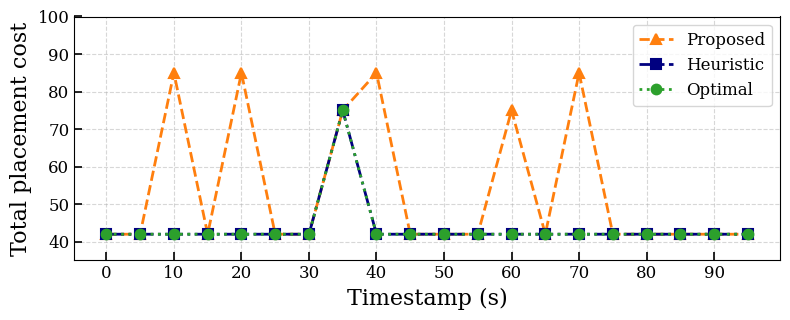

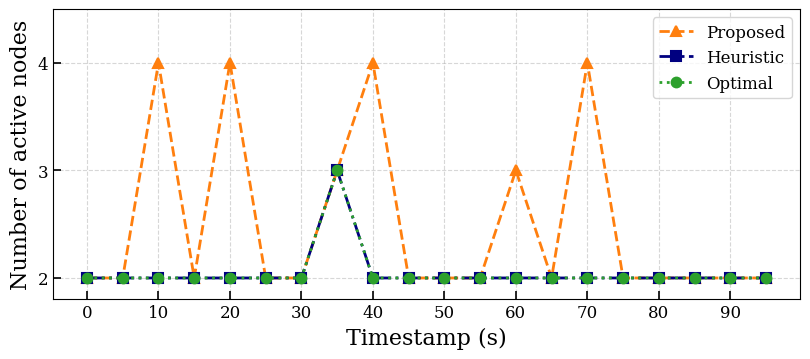

Saved: cost_comparison_time.pdf
Saved: active_nodes_comparison_time.pdf


In [2]:
import matplotlib.pyplot as plt

#/home/cci/Downloads/Latest/Revised/Time_Vary_50N

plt.rcParams['font.family'] = 'serif'

x = comparison_df['timestamp_s'].to_numpy(dtype=int)

cost_drl = comparison_df['cost_ha2c'].to_numpy(dtype=float)
cost_heur = comparison_df['cost_heuristic'].to_numpy(dtype=float)
cost_opt = comparison_df['cost_optimal'].to_numpy(dtype=float)

nodes_drl = comparison_df['nodes_ha2c'].to_numpy(dtype=int)
nodes_heur = comparison_df['nodes_heuristic'].to_numpy(dtype=int)
nodes_opt = comparison_df['nodes_optimal'].to_numpy(dtype=int)

# ------ Plot formatting ------
LINE_WIDTH = 2.0
MARKER_SIZE = 7
MARKER_EDGE_WIDTH = 1.5

AXIS_LABEL_SIZE = 16
TICK_LABEL_SIZE = 12
LEGEND_FONT_SIZE = 12

# ------ Cost plot ------
fig, ax = plt.subplots(figsize=(8, 3.3))

ax.plot(
    x, cost_drl, '--^',
    linewidth=LINE_WIDTH,
    markersize=MARKER_SIZE,
    markeredgewidth=MARKER_EDGE_WIDTH,
    color='tab:orange',
    label='Proposed'
)

ax.plot(
    x, cost_heur, '-.s',
    linewidth=LINE_WIDTH,
    markersize=MARKER_SIZE,
    markeredgewidth=MARKER_EDGE_WIDTH,
    color='navy',
    label='Heuristic'
)

ax.plot(
    x, cost_opt, ':o',
    linewidth=LINE_WIDTH,
    markersize=MARKER_SIZE,
    markeredgewidth=MARKER_EDGE_WIDTH,
    color='tab:green',
    label='Optimal'
)

ax.set_xlabel('Timestamp (s)', fontsize=AXIS_LABEL_SIZE)
ax.set_ylabel('Total placement cost', fontsize=AXIS_LABEL_SIZE)

ax.set_xticks(x if len(x) <= 12 else x[::2])
ax.set_ylim(bottom=35, top=100)

ax.grid(
    which='major',
    linestyle='--',
    linewidth=0.8,
    alpha=0.5
)

ax.tick_params(
    axis='both',
    direction='in',
    labelsize=TICK_LABEL_SIZE,
    width=1.2,
    length=6
)

ax.legend(
    fontsize=LEGEND_FONT_SIZE,
    loc='best',
    frameon=True
)

fig.tight_layout()

cost_plot_path = 'cost_comparison_time.pdf'

fig.savefig(
    cost_plot_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------ Unique active physical node plot ------
fig, ax = plt.subplots(figsize=(8.2, 3.7))

ax.plot(
    x, nodes_drl, '--^',
    linewidth=LINE_WIDTH,
    markersize=MARKER_SIZE,
    markeredgewidth=MARKER_EDGE_WIDTH,
    color='tab:orange',
    label='Proposed'
)

ax.plot(
    x, nodes_heur, '-.s',
    linewidth=LINE_WIDTH,
    markersize=MARKER_SIZE,
    markeredgewidth=MARKER_EDGE_WIDTH,
    color='navy',
    label='Heuristic'
)

ax.plot(
    x, nodes_opt, ':o',
    linewidth=LINE_WIDTH,
    markersize=MARKER_SIZE,
    markeredgewidth=MARKER_EDGE_WIDTH,
    color='tab:green',
    label='Optimal'
)

ax.set_xlabel('Timestamp (s)', fontsize=AXIS_LABEL_SIZE)
ax.set_ylabel('Number of active nodes', fontsize=AXIS_LABEL_SIZE)

ax.set_xticks(x if len(x) <= 12 else x[::2])
ax.set_ylim(bottom=1.8, top=4.5)

ax.yaxis.get_major_locator().set_params(integer=True)

ax.grid(
    which='major',
    linestyle='--',
    linewidth=0.8,
    alpha=0.5
)

ax.tick_params(
    axis='both',
    direction='in',
    labelsize=TICK_LABEL_SIZE,
    width=1.2,
    length=6
)

ax.legend(
    fontsize=LEGEND_FONT_SIZE,
    loc='best',
    frameon=True
)

fig.tight_layout()

nodes_plot_path = 'active_nodes_comparison_time.pdf'

fig.savefig(
    nodes_plot_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()




print('Saved:', cost_plot_path)
print('Saved:', nodes_plot_path)
